In [ ]:
# Brain Stroke CT - SIN393
# Experimento acadêmico; não usar para diagnóstico. Execute no runtime remoto do Google Colab.
%pip -q install kaggle scikit-learn pandas pillow tqdm
import os, sys, json, random, hashlib, subprocess, time
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, torch, torchvision
from PIL import Image
SEED=393
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print({'python':sys.version.split()[0], 'torch':torch.__version__, 'torchvision':torchvision.__version__, 'device':str(DEVICE), 'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None})


{'python': '3.13.15', 'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'device': 'cuda', 'gpu': 'Tesla T4'}


In [ ]:
# Use the ZIP already uploaded to Google Drive; extraction and all image work run on Colab only.
from google.colab import drive
import zipfile
drive.mount('/content/drive')
ZIP_PATH = Path('/content/drive/MyDrive/archive(1).zip')
EXTRACT_ROOT = Path('/content/brain-stroke-ct-dataset')
if not ZIP_PATH.is_file():
    raise FileNotFoundError(f'ZIP not found: {ZIP_PATH}. Place archive(1).zip in My Drive or update ZIP_PATH.')
EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)
if not any(EXTRACT_ROOT.iterdir()):
    with zipfile.ZipFile(ZIP_PATH) as zf:
        root_resolved = EXTRACT_ROOT.resolve()
        for member in zf.infolist():
            destination = (EXTRACT_ROOT / member.filename).resolve()
            if destination != root_resolved and root_resolved not in destination.parents:
                raise ValueError(f'Unsafe path in ZIP: {member.filename}')
        zf.extractall(EXTRACT_ROOT)
expected = {'bleeding', 'ischemia', 'normal'}
roots = [p for p in [EXTRACT_ROOT, *EXTRACT_ROOT.rglob('*')] if p.is_dir() and expected.issubset({q.name.lower() for q in p.iterdir() if q.is_dir()})]
if not roots:
    raise FileNotFoundError('Could not locate Bleeding/Ischemia/Normal folders after extraction.')
DATA_ROOT = roots[0]
print('Dataset root:', DATA_ROOT)
print('External_Test folders:', [str(p) for p in DATA_ROOT.rglob('*') if p.is_dir() and p.name.lower() == 'external_test'])
print('Image files:', sum(p.is_file() and p.suffix.lower() in {'.png','.jpg','.jpeg','.bmp','.tif','.tiff','.webp'} for p in DATA_ROOT.rglob('*')))


Mounted at /content/drive
Dataset root: /content/brain-stroke-ct-dataset/Brain_Stroke_CT_Dataset
External_Test folders: ['/content/brain-stroke-ct-dataset/Brain_Stroke_CT_Dataset/External_Test']
Image files: 9473


In [ ]:
# Audit images, labels, duplicates, metadata and dimensions. Keep External_Test isolated from model development.
IMAGE_EXTS={'.png','.jpg','.jpeg','.bmp','.tif','.tiff','.webp'}
files=[p for p in DATA_ROOT.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
def canonical_label(p):
    parts=[q.lower().replace('_',' ').replace('-',' ') for q in p.parts]
    if any(any(x in s for x in ['hemorr','haemorr','bleed']) for s in parts): return 'hemorrhage'
    if any(any(x in s for x in ['ische','infarct']) for s in parts): return 'ischemia'
    if any(any(x in s for x in ['normal','healthy','no stroke','non stroke','control']) for s in parts): return 'normal'
    return None
rows=[]; errors=[]; hashes={}
for p in files:
    is_external=any(q.name.lower()=='external_test' for q in p.parents)
    try:
        with Image.open(p) as im:
            w,h=im.size; mode=im.mode; im.verify()
        digest=hashlib.sha256(p.read_bytes()).hexdigest()
        rows.append({'path':str(p),'folder':p.parent.name,'label':canonical_label(p),'external_test':is_external,'width':w,'height':h,'mode':mode,'sha256':digest})
        hashes.setdefault(digest,[]).append(str(p))
    except Exception as e: errors.append({'path':str(p),'error':str(e)})
audit=pd.DataFrame(rows)
print('Images:',len(files),'readable:',len(audit),'unreadable:',len(errors),'exact duplicate groups:',sum(len(v)>1 for v in hashes.values()))
if len(audit):
    print('Counts by folder / label / external flag:')
    display(audit.groupby(['folder','label','external_test'],dropna=False).size().rename('count').reset_index())
    print('Most common image dimensions:')
    display(audit.groupby(['width','height']).size().sort_values(ascending=False).head(15))
    unlabeled_external=audit[audit.external_test & audit.label.isna()]
    print('External_Test images without a class in their path:',len(unlabeled_external))
    display(unlabeled_external[['path','folder']].head(10))
metadata_files=[p for p in DATA_ROOT.rglob('*') if p.is_file() and p.suffix.lower() in {'.csv','.tsv','.json','.xlsx'}]
print('Metadata files:',[str(p) for p in metadata_files])
for p in metadata_files:
    if p.suffix.lower() in {'.csv','.tsv'}:
        try: print(p.name,pd.read_csv(p,sep='\t' if p.suffix.lower()=='.tsv' else ',').head(3).to_dict('records'))
        except Exception as e: print('Could not read',p.name,repr(e))
print('Filename examples:',[Path(x).name for x in audit.path.head(25)])
audit.to_csv('/content/auditoria_imagens.csv',index=False)
pd.DataFrame(errors).to_csv('/content/erros_leitura.csv',index=False)
primary=audit[~audit.external_test].copy()
assert len(primary)>0, 'No images found outside External_Test.'
assert primary.label.notna().all(), 'Some non-External_Test paths do not identify a class; inspect the audit before splitting.'
# Audit images, labels, duplicates, metadata and dimensions. Keep External_Test isolated.
IMAGE_EXTS={'.png','.jpg','.jpeg','.bmp','.tif','.tiff','.webp'}
files=[p for p in DATA_ROOT.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
def canonical_label(p):
    parts=[q.lower().replace('_',' ').replace('-',' ') for q in p.parts]
    if any(any(x in s for x in ['hemorr','haemorr','bleed']) for s in parts): return 'hemorrhage'
    if any(any(x in s for x in ['ische','infarct']) for s in parts): return 'ischemia'
    if any(any(x in s for x in ['normal','healthy','no stroke','non stroke','control']) for s in parts): return 'normal'
    return None
rows=[]; errors=[]; hashes={}
for p in files:
    is_external=any(q.name.lower()=='external_test' for q in p.parents)
    try:
        with Image.open(p) as im: w,h=im.size; mode=im.mode; im.verify()
        digest=hashlib.sha256(p.read_bytes()).hexdigest()
        rows.append({'path':str(p),'folder':p.parent.name,'label':canonical_label(p),'external_test':is_external,'width':w,'height':h,'mode':mode,'sha256':digest})
        hashes.setdefault(digest,[]).append(str(p))
    except Exception as e: errors.append({'path':str(p),'error':str(e)})
audit=pd.DataFrame(rows)
print('Images:',len(files),'readable:',len(audit),'unreadable:',len(errors),'exact duplicate groups:',sum(len(v)>1 for v in hashes.values()))
display(audit.groupby(['folder','label','external_test'],dropna=False).size().rename('count').reset_index())
display(audit.groupby(['width','height']).size().sort_values(ascending=False).head(15))
unlabeled_external=audit[audit.external_test & audit.label.isna()]
print('External_Test without class in path:',len(unlabeled_external)); display(unlabeled_external[['path','folder']].head(10))
metadata_files=[p for p in DATA_ROOT.rglob('*') if p.is_file() and p.suffix.lower() in {'.csv','.tsv','.json','.xlsx'}]
print('Metadata files:',[str(p) for p in metadata_files])
for p in metadata_files:
    if p.suffix.lower() in {'.csv','.tsv'}:
        try: print(p.name,pd.read_csv(p,sep='\t' if p.suffix.lower()=='.tsv' else ',').head(3).to_dict('records'))
        except Exception as e: print('Could not read',p.name,repr(e))
print('Filename examples:',[Path(x).name for x in audit.path.head(25)])
audit.to_csv('/content/auditoria_imagens.csv',index=False); pd.DataFrame(errors).to_csv('/content/erros_leitura.csv',index=False)
primary=audit[~audit.external_test].copy()
assert len(primary)>0
assert primary.label.notna().all(), 'Some non-External_Test paths do not identify a class; inspect before splitting.'
assert set(primary.label.unique())=={'normal','ischemia','hemorrhage'}

Images: 9473 readable: 9473 unreadable: 0 exact duplicate groups: 172
Counts by folder / label / external flag:


,folder,label,external_test,count
0,MASKS,NaN,True,200
1,OVERLAY,hemorrhage,False,1093
2,OVERLAY,ischemia,False,1130
3,OVERLAY,NaN,True,200
4,PNG,hemorrhage,False,1093
5,PNG,ischemia,False,1130
6,PNG,normal,False,4427
7,PNG,NaN,True,200


Most common image dimensions:


width  height
512    512       9138
       552         25
       563         20
       574         19
565    512         17
512    562         16
611    512         16
512    540         15
546    512         15
512    636         15
       554         14
       658         14
       759         14
       692         14
       605         13
dtype: int64

External_Test images without a class in their path: 600


,path,folder
4427,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY
4428,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY
4429,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY
4430,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY
4431,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY
4432,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY
4433,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY
4434,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY
4435,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY
4436,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY


... (2 outputs left out)

width  height
512    512       9138
       552         25
       563         20
       574         19
565    512         17
512    562         16
611    512         16
512    540         15
546    512         15
512    636         15
       554         14
       658         14
       759         14
       692         14
       605         13
dtype: int64

External_Test without class in path: 600


,path,folder
4427,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY
4428,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY
4429,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY
4430,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY
4431,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY
4432,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY
4433,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY
4434,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY
4435,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY
4436,/content/brain-stroke-ct-dataset/Brain_Stroke_...,OVERLAY


Metadata files: ['/content/brain-stroke-ct-dataset/Brain_Stroke_CT_Dataset/External_Test/labels.csv']
labels.csv [{'image_id': 10189, 'Stroke': 0}, {'image_id': 10200, 'Stroke': 0}, {'image_id': 10231, 'Stroke': 0}]
Filename examples: ['12129.png', '14571.png', '15074.png', '16435.png', '10551.png', '16904.png', '16761.png', '13765.png', '14678.png', '14050.png', '14359.png', '13138.png', '15585.png', '10655.png', '15182.png', '11325.png', '13986.png', '14356.png', '12558.png', '10044.png', '12389.png', '15264.png', '13844.png', '11027.png', '10524.png']


In [ ]:
# Use only original PNG images; main filenames are numeric image IDs and no patient/study metadata exists.
from sklearn.model_selection import train_test_split
main_df=audit[(~audit.external_test) & (audit.folder.str.lower()=='png')].copy()
assert main_df.label.notna().all()
assert set(main_df.label.unique())=={'normal','ischemia','hemorrhage'}
print('Main PNG images:',len(main_df)); print('Class counts:',main_df.label.value_counts().to_dict())
print('No patient/study IDs found for main set; using image-level split, seed 393.')
train_df,temp_df=train_test_split(main_df,test_size=.30,random_state=SEED,stratify=main_df.label)
val_df,test_df=train_test_split(temp_df,test_size=.50,random_state=SEED,stratify=temp_df.label)
train_df=train_df.copy(); train_df['split']='train'
val_df=val_df.copy(); val_df['split']='validation'
test_df=test_df.copy(); test_df['split']='test'
splits=pd.concat([train_df,val_df,test_df],ignore_index=True)
display(splits.groupby(['split','label']).size().unstack(fill_value=0))
from sklearn.model_selection import train_test_split
main_df=audit[(~audit.external_test)&(audit.folder.str.lower()=='png')].copy()
assert main_df.label.notna().all() and set(main_df.label.unique())=={'normal','ischemia','hemorrhage'}
print('PNG count',len(main_df),'class counts',main_df.label.value_counts().to_dict())
train_df,temp_df=train_test_split(main_df,test_size=.30,random_state=SEED,stratify=main_df.label)
val_df,test_df=train_test_split(temp_df,test_size=.50,random_state=SEED,stratify=temp_df.label)
for frame,name in [(train_df,'train'),(val_df,'validation'),(test_df,'test')]: frame['split']=name
splits=pd.concat([train_df,val_df,test_df],ignore_index=True)
display(splits.groupby(['split','label']).size().unstack(fill_value=0))
splits[['path','label','split']].to_csv('/content/splits_seed393.csv',index=False)

Main PNG images: 6650
Class counts: {'normal': 4427, 'ischemia': 1130, 'hemorrhage': 1093}
No patient/study IDs found for main set; using image-level split, seed 393.


label,hemorrhage,ischemia,normal
split,,,
test,164,170,664
train,765,791,3099
validation,164,169,664


PNG count 6650 class counts {'normal': 4427, 'ischemia': 1130, 'hemorrhage': 1093}


label,hemorrhage,ischemia,normal
split,,,
test,164,170,664
train,765,791,3099
validation,164,169,664


Figura PNG: /content/drive/MyDrive/Brain_Stroke_CT_SIN393_logs/gradcam_exemplos_teste.png
Figura PDF: /content/drive/MyDrive/Brain_Stroke_CT_SIN393_logs/gradcam_exemplos_teste.pdf
Metadados: /content/drive/MyDrive/Brain_Stroke_CT_SIN393_logs/gradcam_exemplos_teste.csv


,arquivo,rotulo_real,classe_predita,prob_normal,prob_isquemia,prob_hemorragia,confianca_predicao,classe_explicada_gradcam
0,/content/brain-stroke-ct-dataset/Brain_Stroke_...,ischemia,ischemia,0.000007,0.999991,0.000002,0.999991,ischemia
1,/content/brain-stroke-ct-dataset/Brain_Stroke_...,ischemia,normal,0.999969,0.000009,0.000022,0.999969,normal


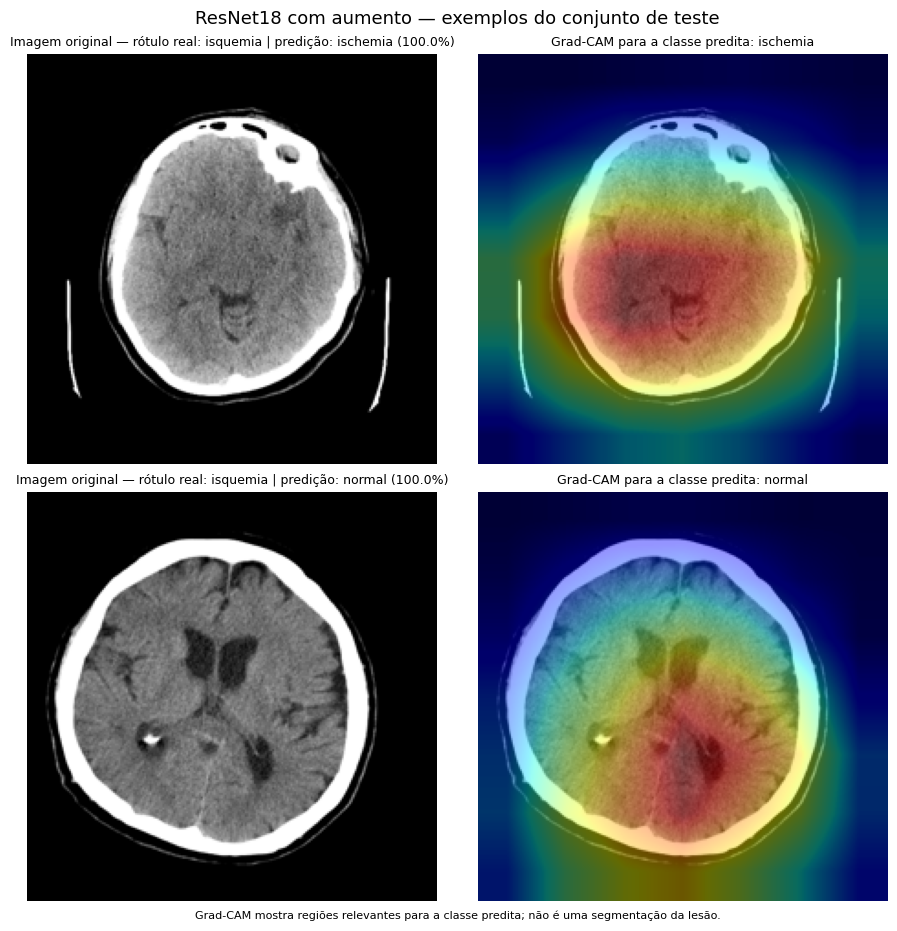

In [ ]:
# Grad-CAM de exemplos reais do teste usando o checkpoint salvo (sem retreinamento)
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from pathlib import Path
import pandas as pd, numpy as np
from PIL import Image
CLASSES=['normal','ischemia','hemorrhage']
LOG_DIR=Path('/content/drive/MyDrive/Brain_Stroke_CT_SIN393_logs')
ckpt=LOG_DIR/'best_resnet18_aug1.pt'
assert ckpt.is_file(), f'Checkpoint não encontrado: {ckpt}'
cam_model=models.resnet18(weights=None)
cam_model.fc=nn.Linear(cam_model.fc.in_features,3)
cam_model.load_state_dict(torch.load(ckpt,map_location=DEVICE,weights_only=True))
cam_model=cam_model.to(DEVICE).eval()
mean,std=models.ResNet18_Weights.DEFAULT.transforms().mean,models.ResNet18_Weights.DEFAULT.transforms().std
cam_tf=transforms.Compose([transforms.Resize((224,224)),transforms.ToTensor(),transforms.Normalize(mean,std)])
records=[]
with torch.inference_mode():
    for start in range(0,len(test_df),32):
        batch_rows=test_df.iloc[start:start+32]
        xb=torch.stack([cam_tf(Image.open(p).convert('RGB')) for p in batch_rows.path]).to(DEVICE)
        logits=cam_model(xb); probs=logits.softmax(1).cpu().numpy(); pred=logits.argmax(1).cpu().numpy()
        for row,pb,pr in zip(batch_rows.itertuples(),probs,pred):
            records.append({'path':row.path,'true':row.label,'pred':CLASSES[int(pr)],'p_normal':float(pb[0]),'p_ischemia':float(pb[1]),'p_hemorrhage':float(pb[2]),'confidence':float(pb[int(pr)])})
pred_df=pd.DataFrame(records)
hits=pred_df[(pred_df.true=='ischemia')&(pred_df.pred=='ischemia')]
misses=pred_df[(pred_df.true=='ischemia')&(pred_df.pred!='ischemia')]
assert len(hits)>0 and len(misses)>0, 'Sem exemplos positivos e negativos de isquemia no teste.'
chosen=[hits.sort_values('p_ischemia',ascending=False).iloc[0],misses.sort_values('confidence',ascending=False).iloc[0]]
cam_results=[]
for rec in chosen:
    img=Image.open(rec.path).convert('RGB').resize((224,224))
    x=cam_tf(Image.open(rec.path).convert('RGB')).unsqueeze(0).to(DEVICE)
    act={}
    def capture(module,inputs,output):
        act['feature']=output
        output.retain_grad()
    hook=cam_model.layer4[-1].register_forward_hook(capture)
    cam_model.zero_grad(set_to_none=True)
    logits=cam_model(x); target=int(logits.argmax(1).item()); logits[0,target].backward()
    feat=act['feature'][0]; grad=act['feature'].grad[0]; weights=grad.mean(dim=(1,2))
    cam=F.relu((weights[:,None,None]*feat).sum(0)); cam=cam-cam.min(); cam=cam/(cam.max()+1e-8)
    cam=F.interpolate(cam[None,None],size=(224,224),mode='bilinear',align_corners=False)[0,0].detach().cpu().numpy()
    hook.remove(); cam_results.append((rec,img,cam,CLASSES[target]))
fig,axes=plt.subplots(2,2,figsize=(9,9),constrained_layout=True)
for i,(rec,img,cam,target_name) in enumerate(cam_results):
    axes[i,0].imshow(img,cmap='gray')
    axes[i,0].set_title('Imagem original — rótulo real: isquemia | predição: '+str(rec.pred)+' ('+format(rec.confidence,'.1%')+')',fontsize=9)
    axes[i,1].imshow(img,cmap='gray'); axes[i,1].imshow(cam,cmap='jet',alpha=0.42,vmin=0,vmax=1)
    axes[i,1].set_title('Grad-CAM para a classe predita: '+target_name,fontsize=9)
    for ax in axes[i]: ax.axis('off')
fig.suptitle('ResNet18 com aumento — exemplos do conjunto de teste',fontsize=13)
fig.text(0.5,-0.015,'Grad-CAM mostra regiões relevantes para a classe predita; não é uma segmentação da lesão.',ha='center',fontsize=8)
png=LOG_DIR/'gradcam_exemplos_teste.png'; pdf=LOG_DIR/'gradcam_exemplos_teste.pdf'
fig.savefig(png,dpi=300,bbox_inches='tight'); fig.savefig(pdf,bbox_inches='tight')
meta=pd.DataFrame([{'arquivo':str(r.path),'rotulo_real':r.true,'classe_predita':r.pred,'prob_normal':r.p_normal,'prob_isquemia':r.p_ischemia,'prob_hemorragia':r.p_hemorrhage,'confianca_predicao':r.confidence,'classe_explicada_gradcam':t} for r,im,cm,t in cam_results])
meta.to_csv(LOG_DIR/'gradcam_exemplos_teste.csv',index=False)
print('Figura PNG:',png); print('Figura PDF:',pdf); print('Metadados:',LOG_DIR/'gradcam_exemplos_teste.csv'); display(meta)
plt.show()

DEVICE: cuda | imagens no teste: 998 | salvo em: /content/gdrive/MyDrive/Brain_Stroke_CT_SIN393_logs


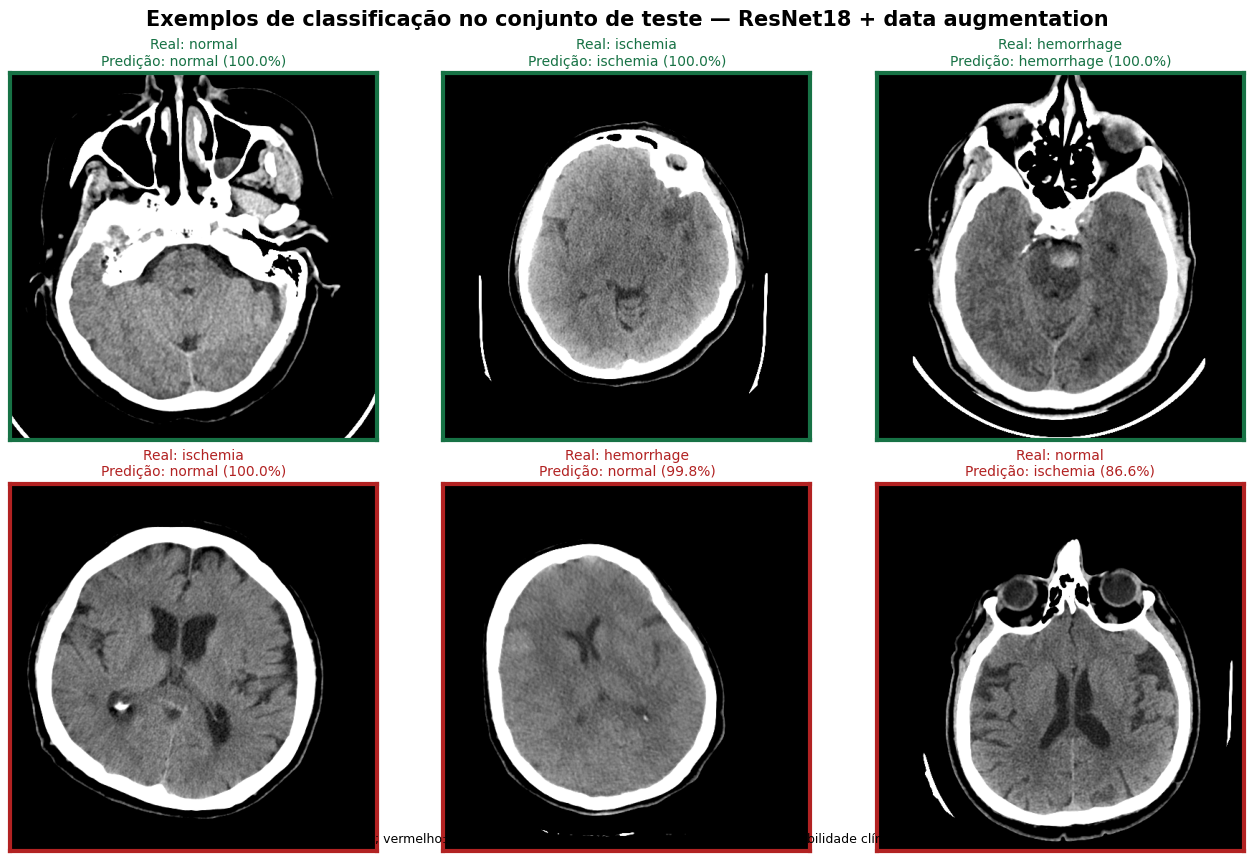

,example_type,true_label,predicted_label,confidence
126,Correta,normal,normal,1.000000
104,Correta,ischemia,ischemia,0.999991
348,Correta,hemorrhage,hemorrhage,0.999998
386,Incorreta,ischemia,normal,0.999969
507,Incorreta,hemorrhage,normal,0.998399
288,Incorreta,normal,ischemia,0.865754


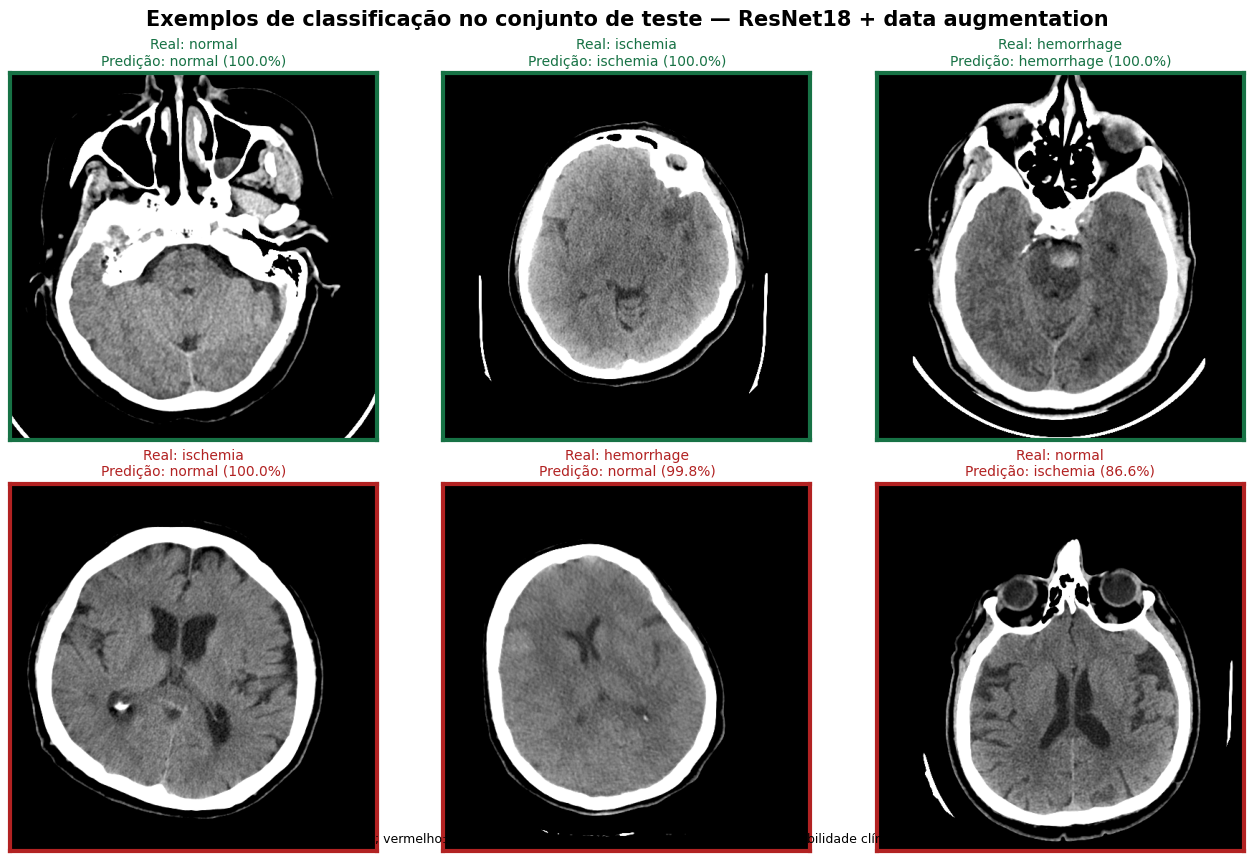

In [ ]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
FIG_DIR=Path('/content/gdrive/MyDrive/Brain_Stroke_CT_SIN393_logs')
class_names=['normal','ischemia','hemorrhage']; label_to_id={n:i for i,n in enumerate(class_names)}
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
test_df=pd.read_csv(FIG_DIR/'splits_seed393.csv'); test_df=test_df[test_df['split']=='test'].reset_index(drop=True)
weights_meta=models.ResNet18_Weights.DEFAULT.transforms(); transform=transforms.Compose([transforms.Resize((224,224)),transforms.ToTensor(),transforms.Normalize(weights_meta.mean,weights_meta.std)])
class TestImages(Dataset):
    def __len__(self): return len(test_df)
    def __getitem__(self,idx):
        r=test_df.iloc[idx]
        with Image.open(r['path']) as im: x=transform(im.convert('RGB'))
        return x,label_to_id[r['label']]
model=models.resnet18(weights=None); model.fc=nn.Linear(model.fc.in_features,3)
model.load_state_dict(torch.load(FIG_DIR/'best_resnet18_aug1.pt',map_location=device,weights_only=True)); model=model.to(device).eval()
loader=DataLoader(TestImages(),batch_size=32,shuffle=False,num_workers=2); probs_all=[]; true_all=[]
with torch.inference_mode():
    for xb,yb in loader: probs_all.append(torch.softmax(model(xb.to(device)),dim=1).cpu().numpy()); true_all.extend(yb.numpy().tolist())
probs=np.concatenate(probs_all); pred=probs.argmax(axis=1); rows=test_df.copy(); rows['true_id']=true_all; rows['pred_id']=pred; rows['confidence']=probs.max(axis=1)
for j,n in enumerate(class_names): rows['p_'+n]=probs[:,j]
chosen=[]
for c in range(3):
    r=rows[(rows.true_id==c)&(rows.pred_id==c)].sort_values('confidence',ascending=False).iloc[0].copy(); r['example_type']='Correta'; chosen.append(r)
for t,p in [(1,0),(2,0),(0,1)]:
    r=rows[(rows.true_id==t)&(rows.pred_id==p)].sort_values('confidence',ascending=False).iloc[0].copy(); r['example_type']='Incorreta'; chosen.append(r)
fig,axes=plt.subplots(2,3,figsize=(13,8.5),constrained_layout=True); fig.suptitle('Exemplos de classificação no conjunto de teste — ResNet18 + data augmentation',fontsize=15,fontweight='bold')
for ax,r in zip(axes.flat,chosen):
    with Image.open(r['path']) as im: ax.imshow(im.convert('L'),cmap='gray')
    truth=class_names[int(r['true_id'])]; prediction=class_names[int(r['pred_id'])]; color='#177245' if r['example_type']=='Correta' else '#b22222'
    ax.set_title('Real: '+truth+'\nPredição: '+prediction+' ('+format(float(r['confidence'])*100,'.1f')+'%)',fontsize=10,color=color); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_edgecolor(color); sp.set_linewidth(3)
fig.text(.5,.015,'Verde: correta; vermelho: incorreta. Confiança = maior saída softmax; não é probabilidade clínica calibrada.',ha='center',fontsize=9)
base=FIG_DIR/'prediction_examples_test'; fig.savefig(str(base)+'.png',dpi=300,bbox_inches='tight'); fig.savefig(str(base)+'.pdf',bbox_inches='tight')
metadata=pd.DataFrame(chosen); metadata['true_label']=metadata.true_id.map(dict(enumerate(class_names))); metadata['predicted_label']=metadata.pred_id.map(dict(enumerate(class_names)))
metadata[['path','example_type','true_label','predicted_label','confidence','p_normal','p_ischemia','p_hemorrhage']].to_csv(FIG_DIR/'prediction_examples_test.csv',index=False)
print('DEVICE:',device,'| imagens no teste:',len(test_df),'| salvo em:',FIG_DIR)
display(fig); display(metadata[['example_type','true_label','predicted_label','confidence']])

In [ ]:
from torch import nn
from torch.utils.data import Dataset,DataLoader
from torchvision import transforms,models
from sklearn.metrics import f1_score,accuracy_score,classification_report,confusion_matrix
CLASSES=['normal','ischemia','hemorrhage']; LABEL_TO_ID={c:i for i,c in enumerate(CLASSES)}
SIZE=224; BATCH_SIZE=32 if torch.cuda.is_available() else 8; MAX_EPOCHS=12; PATIENCE=3
mean,std=models.ResNet18_Weights.DEFAULT.transforms().mean,models.ResNet18_Weights.DEFAULT.transforms().std
base_tf=transforms.Compose([transforms.Resize((SIZE,SIZE)),transforms.ToTensor(),transforms.Normalize(mean,std)])
aug_tf=transforms.Compose([transforms.Resize((SIZE,SIZE)),transforms.RandomAffine(degrees=7,translate=(.03,.03)),transforms.ColorJitter(brightness=.12,contrast=.12),transforms.ToTensor(),transforms.Normalize(mean,std)])
class CTDataset(Dataset):
    def __init__(self,df,augment=False): self.df=df.reset_index(drop=True); self.tf=aug_tf if augment else base_tf
    def __len__(self): return len(self.df)
    def __getitem__(self,i):
        r=self.df.iloc[i]
        with Image.open(r.path) as im: x=self.tf(im.convert('RGB'))
        return x,LABEL_TO_ID[r.label]
def make_model(arch):
    if arch=='resnet18':
        m=models.resnet18(weights=models.ResNet18_Weights.DEFAULT); m.fc=nn.Linear(m.fc.in_features,3)
    else:
        m=models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.DEFAULT); m.classifier[-1]=nn.Linear(m.classifier[-1].in_features,3)
    return m.to(DEVICE)
def score(model,loader):
    model.eval(); ys=[]; ps=[]
    with torch.no_grad():
        for x,y in loader: ps.extend(model(x.to(DEVICE)).argmax(1).cpu().tolist()); ys.extend(y.tolist())
    return f1_score(ys,ps,average='macro'),np.array(ys),np.array(ps)
def fit(arch,augment):
    tr=DataLoader(CTDataset(train_df,augment),batch_size=BATCH_SIZE,shuffle=True,num_workers=2,pin_memory=torch.cuda.is_available())
    va=DataLoader(CTDataset(val_df),batch_size=BATCH_SIZE,shuffle=False,num_workers=2)
    counts=Counter(train_df.label); cw=torch.tensor([len(train_df)/(3*counts[c]) for c in CLASSES],dtype=torch.float32,device=DEVICE)
    model=make_model(arch); loss_fn=nn.CrossEntropyLoss(weight=cw); opt=torch.optim.AdamW(model.parameters(),lr=1e-4,weight_decay=1e-4)
    best=-1; stale=0; history=[]; ckpt=f'/content/best_{arch}_aug{int(augment)}.pt'
    for epoch in range(MAX_EPOCHS):
        start=time.time(); model.train(); total=0.
        for x,y in tr:
            x=x.to(DEVICE); y=y.to(DEVICE); opt.zero_grad(set_to_none=True); loss=loss_fn(model(x),y); loss.backward(); opt.step(); total+=loss.item()*len(y)
        vf1,_,_=score(model,va); history.append({'epoch':epoch+1,'train_loss':total/len(train_df),'val_macro_f1':vf1,'seconds':time.time()-start}); print(arch,augment,history[-1])
        if vf1>best: best=vf1; stale=0; torch.save(model.state_dict(),ckpt)
        else: stale+=1
        if stale>=PATIENCE: break
    return ckpt,pd.DataFrame(history)
runs={}
for arch in ['resnet18','mobilenet_v3_large']:
    for augment in [False,True]: runs[(arch,augment)]=fit(arch,augment)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 174MB/s]


resnet18 False {'epoch': 1, 'train_loss': 0.4921312244827074, 'val_macro_f1': 0.8705379503182318, 'seconds': 34.65477752685547}
resnet18 False {'epoch': 2, 'train_loss': 0.14047291028192296, 'val_macro_f1': 0.9180743272222734, 'seconds': 32.21743321418762}
resnet18 False {'epoch': 3, 'train_loss': 0.07016481885528462, 'val_macro_f1': 0.9053565311947055, 'seconds': 33.13858985900879}
resnet18 False {'epoch': 4, 'train_loss': 0.05243579918212556, 'val_macro_f1': 0.9360140173008347, 'seconds': 32.68991208076477}
resnet18 False {'epoch': 5, 'train_loss': 0.034394174260032294, 'val_macro_f1': 0.9174008392712151, 'seconds': 32.80715298652649}
resnet18 False {'epoch': 6, 'train_loss': 0.03370200053145499, 'val_macro_f1': 0.9012016960491729, 'seconds': 33.06045389175415}
resnet18 False {'epoch': 7, 'train_loss': 0.03724155720407353, 'val_macro_f1': 0.8612858924031205, 'seconds': 32.93814730644226}
resnet18 True {'epoch': 1, 'train_loss': 0.56329187169495, 'val_macro_f1': 0.7830354208857694, 's

100%|██████████| 21.1M/21.1M [00:00<00:00, 131MB/s] 


mobilenet_v3_large False {'epoch': 1, 'train_loss': 0.6740694656279879, 'val_macro_f1': 0.7190407415852711, 'seconds': 31.331981897354126}
mobilenet_v3_large False {'epoch': 2, 'train_loss': 0.25947691970749903, 'val_macro_f1': 0.818238341336227, 'seconds': 32.16636824607849}
mobilenet_v3_large False {'epoch': 3, 'train_loss': 0.1067494242775197, 'val_macro_f1': 0.8740101678317113, 'seconds': 31.8357572555542}
mobilenet_v3_large False {'epoch': 4, 'train_loss': 0.05533099113838501, 'val_macro_f1': 0.8806718318889265, 'seconds': 31.457980155944824}
mobilenet_v3_large False {'epoch': 5, 'train_loss': 0.038034557255043, 'val_macro_f1': 0.9010701196541904, 'seconds': 31.551387548446655}
mobilenet_v3_large False {'epoch': 6, 'train_loss': 0.028630945470212096, 'val_macro_f1': 0.8896393996611539, 'seconds': 31.846390962600708}
mobilenet_v3_large False {'epoch': 7, 'train_loss': 0.013728837754825484, 'val_macro_f1': 0.9072655866470299, 'seconds': 31.84752655029297}
mobilenet_v3_large False {'

In [ ]:
test_loader=DataLoader(CTDataset(test_df),batch_size=BATCH_SIZE,shuffle=False,num_workers=2)
summary=[]; details=[]
for (arch,augment),(ckpt,hist) in runs.items():
    model=make_model(arch); model.load_state_dict(torch.load(ckpt,map_location=DEVICE,weights_only=True))
    macro,ys,ps=score(model,test_loader)
    report=classification_report(ys,ps,labels=list(range(3)),target_names=CLASSES,output_dict=True,zero_division=0)
    cm=confusion_matrix(ys,ps,labels=list(range(3)))
    summary.append({'architecture':arch,'augmentation':augment,'accuracy':accuracy_score(ys,ps),'macro_f1':macro,'weighted_f1':f1_score(ys,ps,average='weighted')})
    details.append({'architecture':arch,'augmentation':augment,'report':report,'confusion_matrix':cm.tolist()})
    hist.to_csv(f'/content/history_{arch}_aug{int(augment)}.csv',index=False)
pd.DataFrame(summary).to_csv('/content/test_summary.csv',index=False)
Path('/content/test_details.json').write_text(json.dumps(details,indent=2))
display(pd.DataFrame(summary)); print(json.dumps(details,indent=2))


,architecture,augmentation,accuracy,macro_f1,weighted_f1
0,resnet18,False,0.948898,0.930320,0.947863
1,resnet18,True,0.961924,0.948963,0.961337
2,mobilenet_v3_large,False,0.930862,0.902582,0.929429
3,mobilenet_v3_large,True,0.944890,0.924916,0.945183


[
  {
    "architecture": "resnet18",
    "augmentation": false,
    "report": {
      "normal": {
        "precision": 0.9491279069767442,
        "recall": 0.983433734939759,
        "f1-score": 0.9659763313609467,
        "support": 664.0
      },
      "ischemia": {
        "precision": 0.9455782312925171,
        "recall": 0.8176470588235294,
        "f1-score": 0.8769716088328076,
        "support": 170.0
      },
      "hemorrhage": {
        "precision": 0.950920245398773,
        "recall": 0.9451219512195121,
        "f1-score": 0.9480122324159022,
        "support": 164.0
      },
      "accuracy": 0.9488977955911824,
      "macro avg": {
        "precision": 0.9485421278893447,
        "recall": 0.9154009149942669,
        "f1-score": 0.9303200575365521,
        "support": 998.0
      },
      "weighted avg": {
        "precision": 0.9488177853684218,
        "recall": 0.9488977955911824,
        "f1-score": 0.947863190021497,
        "support": 998.0
      }
    },
    "con

In [ ]:
from pathlib import Path; from shutil import copy2; from datetime import datetime; LOG_DIR=Path('/content/drive/MyDrive/Brain_Stroke_CT_SIN393_logs'); LOG_DIR.mkdir(parents=True,exist_ok=True); [copy2(Path('/content')/n,LOG_DIR/n) for n in ['splits_seed393.csv','auditoria_imagens.csv','erros_leitura.csv','test_summary.csv','test_details.json'] if (Path('/content')/n).exists()]; [(h.to_csv(LOG_DIR/('history_'+a+'_aug'+str(int(g))+'.csv'),index=False),copy2(Path(c),LOG_DIR/Path(c).name) if Path(c).exists() else None) for (a,g),(c,h) in runs.items()]; lines=['Brain Stroke CT - SIN393','Gerado em: '+datetime.now().isoformat(timespec='seconds'),'Dispositivo: '+str(DEVICE)]+['{}; augmentation={}; best_epoch={}; val_macro_f1={:.6f}'.format(a,g,int(h.loc[h.val_macro_f1.idxmax()].epoch),h.val_macro_f1.max()) for (a,g),(c,h) in runs.items()]+['epoch={}; train_loss={:.6f}; val_macro_f1={:.6f}; seconds={:.2f}'.format(r.epoch,r.train_loss,r.val_macro_f1,r.seconds) for (a,g),(c,h) in runs.items() for r in h.itertuples()]+['TEST {}; augmentation={}; accuracy={:.6f}; macro_f1={:.6f}; weighted_f1={:.6f}'.format(x['architecture'],x['augmentation'],x['accuracy'],x['macro_f1'],x['weighted_f1']) for x in summary]; (LOG_DIR/'training_log.txt').write_text(chr(10).join(lines)+chr(10),encoding='utf-8'); print('Log and artifacts saved:',LOG_DIR, sorted(p.name for p in LOG_DIR.iterdir()))

Log and artifacts saved: /content/drive/MyDrive/Brain_Stroke_CT_SIN393_logs ['auditoria_imagens.csv', 'best_mobilenet_v3_large_aug0.pt', 'best_mobilenet_v3_large_aug1.pt', 'best_resnet18_aug0.pt', 'best_resnet18_aug1.pt', 'erros_leitura.csv', 'history_mobilenet_v3_large_aug0.csv', 'history_mobilenet_v3_large_aug1.csv', 'history_resnet18_aug0.csv', 'history_resnet18_aug1.csv', 'splits_seed393.csv', 'test_details.json', 'test_summary.csv', 'training_log.txt']


In [ ]:
# Auditoria diagnóstica de duplicatas entre partições (não treina nem altera os splits)
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import pandas as pd
root=Path('/content/drive/MyDrive/Brain_Stroke_CT_SIN393_logs')
audit=pd.read_csv(root/'auditoria_imagens.csv')
splits=pd.read_csv(root/'splits_seed393.csv')
main=audit[(~audit['external_test'].astype(bool)) & (audit['folder'].str.lower()=='png')][['path','label','sha256']]
joined=main.merge(splits[['path','split']],on='path',how='inner')
groups=(joined.groupby('sha256').agg(n=('path','size'),n_splits=('split','nunique'),splits=('split',lambda x: ','.join(sorted(set(x)))),n_labels=('label','nunique')).reset_index())
cross=groups[(groups['n']>1)&(groups['n_splits']>1)]
print('PNG principais:',len(joined),'| hashes repetidos na partição:',int((groups.n>1).sum()))
print('Grupos exatos repetidos entre partições:',len(cross))
print('Imagens envolvidas nesses grupos:',int(cross.n.sum()))
print('Grupos que cruzam treino/teste:',int(cross.splits.str.contains('test').sum()))
print('Hashes com rótulos diferentes:',int((groups.n_labels>1).sum()))
print('Partições por grupo duplicado cruzado:')
display(cross[['n','splits','n_labels']].value_counts().rename('grupos').reset_index())

KeyboardInterrupt: 